**Hidden Groundwater Contamination Patterns in Tamil Nadu Using Python**

**Dataset Information**

Dataset: Ground Water Quality — Manual Chemical Parameters

Source: Central Ground Water Board (CGWB), Government of India

Portal: National Water Data Portal

Location: Tamil Nadu, India

Year / Timeline: 2020–2023

Domain: Environmental Analytics / Water Quality

File Format: CSV

**Project Objectives**


Analyze groundwater quality across districts in Tamil Nadu.

Identify districts with higher chemical concentrations.

Study relationships between major groundwater chemical parameters.

Identify unusual groundwater measurements and suggest areas requiring further monitoring.

In [50]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
# Load the Dataset from GitHub

dataset_url = "https://raw.githubusercontent.com/Vishal130108/Hidden-Groundwater-Contamination-Patterns-in-Tamil-Nadu-Using-Python/refs/heads/main/9946e904-573a-4fca-8eec-d259a27e8903.csv"

df = pd.read_csv(dataset_url)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (433, 47)


,_id,SlNo,Station,Agency,State LGD Code,State,District LGD Code,District,Tehsil,Block,...,Iron(mg/L),Arsenic (mg/L),Uranium(mg/L),Manganese (mg/L),Copper (mg/L),Lead (mg/L),Zinc (mg/L),Nickel (mg/L),Cadmium (mg/L),Chromium (mg/L)
0,4,4,Abaddaranapuram,CGWB,33,Tamil Nadu,570,Cuddalore,CUDDALORE,KURINCHIPADI,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,22,22,Abishekapatti,CGWB,33,Tamil Nadu,592,Tirunelveli,TIRUNELVELI,MANUR,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,28,28,Acharapakkam,CGWB,33,Tamil Nadu,574,Kancheepuram,Madhuranthagam,ACHARAPAKKAM,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,56,56,Adyar,CGWB,33,Tamil Nadu,568,Chennai,CHENNAI,CHENNAI,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,57,57,Adyar,CGWB,33,Tamil Nadu,568,Chennai,CHENNAI,CHENNAI,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Initial Exploratory Data Analysis**

In [52]:
# Initial EDA

print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe(include='all').T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 433 entries, 0 to 432
Data columns (total 47 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   _id                                 433 non-null    int64  
 1   SlNo                                433 non-null    int64  
 2   Station                             433 non-null    object 
 3   Agency                              433 non-null    object 
 4   State LGD Code                      433 non-null    int64  
 5   State                               433 non-null    object 
 6   District LGD Code                   433 non-null    int64  
 7   District                            433 non-null    object 
 8   Tehsil                              433 non-null    object 
 9   Block                               433 non-null    object 
 10  Village                             433 non-null    object 
 11  River                   

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
_id,433.0,NaN,NaN,NaN,4012.849885,2448.745338,4.0,1818.0,4069.0,5989.0,8419.0
SlNo,433.0,NaN,NaN,NaN,4012.849885,2448.745338,4.0,1818.0,4069.0,5989.0,8419.0
Station,433,357,Attipattu,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Agency,433,1,CGWB,433,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State LGD Code,433.0,NaN,NaN,NaN,33.0,0.0,33.0,33.0,33.0,33.0,33.0
State,433,1,Tamil Nadu,433,NaN,NaN,NaN,NaN,NaN,NaN,NaN
District LGD Code,433.0,NaN,NaN,NaN,582.17552,12.262622,568.0,574.0,577.0,589.0,634.0
District,433,25,Kancheepuram,58,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tehsil,433,115,St.Thomas,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Block,433,164,St.Thomas,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Data Cleaning,Data Transformation and Feature Engineering**

Handle duplicates

Handle missing values (impute or drop)

column name rename or dropping unwanted columns

Treat outliers if required(optional)

Convert data types if needed

Data Transformation or Data Wrangling

Final EDA

In [53]:
# Check and Remove Duplicates

print("Duplicate Records Before:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

print("Duplicate Records After:", df.duplicated().sum())
print("Dataset Shape:", df.shape)

Duplicate Records Before: 0
Duplicate Records After: 0
Dataset Shape: (433, 47)


In [54]:
# Find Missing Values

missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing %': missing_percentage
})

print(missing_summary[missing_summary['Missing Count'] > 0].to_string())

                                    Missing Count  Missing %
Potential of Hydrogen (pH)                      1       0.23
Electric Conductivity (I 1/4 S/cm)              2       0.46
Total Dissolved Solids (mg/L)                 290      66.97
Carbonate (mg/L)                              101      23.33
Bicarbonate (mg/L)                              1       0.23
Total Alkalinity (mg/L as CaCO3)              433     100.00
Chloride (mg/L)                                 1       0.23
Nitrate N (mgN/L)                             433     100.00
Sulphate (mg/L)                                 4       0.92
Phosphate(mg/L)                               433     100.00
Silica(mg/L)                                  433     100.00
Fluoride (mg/L)                               433     100.00
Total Hardness (mgCaCO3/L)                      3       0.69
Calcium (mg/L)                                  1       0.23
Magnesium (mg/L)                                1       0.23
Sodium (mg/L)           

In [55]:
# Handle Missing Values

# Remove completely empty columns
df.dropna(axis=1, how='all', inplace=True)

# Fill small gaps in numeric columns using median
for col in df.select_dtypes(include='number').columns:
    missing_pct = df[col].isna().mean() * 100
    if 0 < missing_pct <= 5:
        df[col] = df[col].fillna(df[col].median())

print("Dataset Shape After Cleaning:", df.shape)

Dataset Shape After Cleaning: (433, 32)


In [56]:
# Recheck Missing Values

print("Dataset Shape:", df.shape)
print("\nRemaining Missing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0].to_string())

# Data Transformation / Data Wrangling
print(df.columns.tolist())
print([col for col in df.columns if 'date' in col.lower() or 'year' in col.lower()])

Dataset Shape: (433, 32)

Remaining Missing Values:
Total Dissolved Solids (mg/L)    290
Carbonate (mg/L)                 101
Uranium(mg/L)                    291
['_id', 'SlNo', 'Station', 'Agency', 'State LGD Code', 'State', 'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River', 'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River', 'Latitude', 'Longitude', 'Data Acquisition Time', 'Potential of Hydrogen (pH)', 'Electric Conductivity (I 1/4 S/cm)', 'Total Dissolved Solids (mg/L)', 'Carbonate (mg/L)', 'Bicarbonate (mg/L)', 'Chloride (mg/L)', 'Sulphate (mg/L)', 'Total Hardness (mgCaCO3/L)', 'Calcium (mg/L)', 'Magnesium (mg/L)', 'Sodium (mg/L)', 'Uranium(mg/L)']
[]


In [57]:
# Data Transformation / Data Wrangling

df['District'] = df['District'].astype(str).str.strip().str.title()

df['Data Acquisition Time'] = pd.to_datetime(
    df['Data Acquisition Time'], errors='coerce', dayfirst=True
)

df['Sampling_Year'] = df['Data Acquisition Time'].dt.year
df['Sampling_Month'] = df['Data Acquisition Time'].dt.month

df['pH_Category'] = pd.cut(
    df['Potential of Hydrogen (pH)'],
    bins=[-float('inf'), 6.5, 8.5, float('inf')],
    labels=['Below Range', 'Within Range', 'Above Range'],
    include_lowest=True
)

df.loc[df['Potential of Hydrogen (pH)'] == 6.5, 'pH_Category'] = 'Within Range'

display(df[['District', 'Sampling_Year', 'Sampling_Month', 'pH_Category']].head())

,District,Sampling_Year,Sampling_Month,pH_Category
0,Cuddalore,2021,6,Within Range
1,Tirunelveli,2021,6,Within Range
2,Kancheepuram,2021,6,Within Range
3,Chennai,2020,6,Within Range
4,Chennai,2021,6,Within Range


**Note on Year-Based Analysis**

The Sampling_Year and Sampling_Month columns were derived from Data Acquisition Time. Therefore, they represent the data acquisition period and may not reflect the exact groundwater sampling date. Year-wise comparisons should be interpreted with this limitation in mind.

In [58]:
# Final EDA

print("Final Dataset Shape:", df.shape)
print("Total Districts:", df['District'].nunique())
print("Sampling Years:", sorted(df['Sampling_Year'].dropna().unique()))

print("\nSamples by Year:")
display(df['Sampling_Year'].value_counts().sort_index())

print("\nSummary of Key Chemical Parameters:")
display(df[[
    'Potential of Hydrogen (pH)',
    'Electric Conductivity (I 1/4 S/cm)',
    'Total Dissolved Solids (mg/L)',
    'Total Hardness (mgCaCO3/L)',
    'Uranium(mg/L)'
]].describe().round(2))

Final Dataset Shape: (433, 35)
Total Districts: 25
Sampling Years: [np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023)]

Samples by Year:


,count
Sampling_Year,
2020,54
2021,235
2022,140
2023,4



Summary of Key Chemical Parameters:


,Potential of Hydrogen (pH),Electric Conductivity (I 1/4 S/cm),Total Dissolved Solids (mg/L),Total Hardness (mgCaCO3/L),Uranium(mg/L)
count,433.00,433.00,143.00,433.00,142.00
mean,7.52,1781.60,1189.87,490.76,0.01
std,0.33,1349.02,804.53,344.87,0.02
min,4.90,23.00,136.00,14.00,0.00
25%,7.30,960.00,780.00,270.00,0.00
50%,7.50,1461.00,1036.00,420.00,0.00
75%,7.70,2330.00,1474.00,630.00,0.00
max,8.50,10360.00,5588.00,2780.00,0.19


**Final EDA Result & Interpretation**

The cleaned dataset contains 433 groundwater records from 25 districts in Tamil Nadu, covering 2020–2023. The average pH is 7.52, while the median TDS and hardness values are 1,036 mg/L and 420 mg/L, respectively. Electrical conductivity and hardness show considerable variation across samples. TDS and uranium have fewer valid observations, so their results require careful interpretation. Most records belong to 2021, indicating uneven yearly data coverage.

**Statistical Analysis & Visualizations**

,mean,median,mode
Potential of Hydrogen (pH),7.52,7.5,7.4
Electric Conductivity (I 1/4 S/cm),1781.60,1461.0,2100.0
Total Dissolved Solids (mg/L),1189.87,1036.0,1323.0
Total Hardness (mgCaCO3/L),490.76,420.0,410.0
Uranium(mg/L),0.01,0.0,0.0


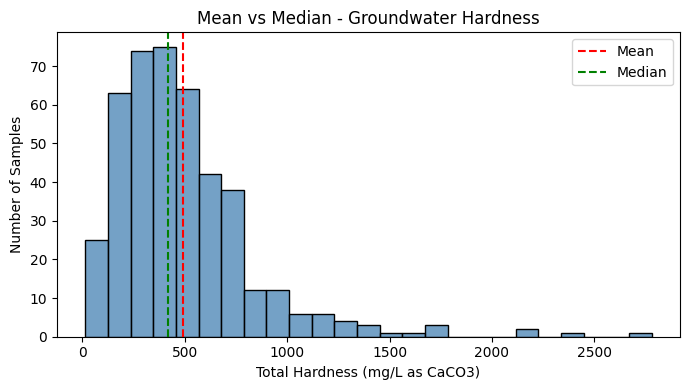

In [59]:
# Measures of Central Tendency

chemical_columns = [
    'Potential of Hydrogen (pH)',
    'Electric Conductivity (I 1/4 S/cm)',
    'Total Dissolved Solids (mg/L)',
    'Total Hardness (mgCaCO3/L)',
    'Uranium(mg/L)'
]

central_tendency = df[chemical_columns].agg(['mean', 'median']).T
central_tendency['mode'] = df[chemical_columns].mode().iloc[0]

display(central_tendency.round(2))

# Mean vs Median - Total Hardness
plt.figure(figsize=(7, 4))
sns.histplot(df['Total Hardness (mgCaCO3/L)'], bins=25, color='steelblue')

plt.axvline(df['Total Hardness (mgCaCO3/L)'].mean(),
            color='red', linestyle='--', label='Mean')

plt.axvline(df['Total Hardness (mgCaCO3/L)'].median(),
            color='green', linestyle='--', label='Median')

plt.title('Mean vs Median - Groundwater Hardness')
plt.xlabel('Total Hardness (mg/L as CaCO3)')
plt.ylabel('Number of Samples')
plt.legend()
plt.tight_layout()
plt.show()

**Result & Interpretation**

The analysis compares the mean, median, and mode of major groundwater chemical parameters. Total hardness has a mean of 490.76 mg/L and a median of 420 mg/L, indicating that higher measurements influence the average. The histogram shows that most groundwater samples have relatively lower hardness values, while a few samples contain unusually high measurements. Therefore, the median provides a useful measure of typical groundwater hardness.

,Variance,Standard Deviation
Potential of Hydrogen (pH),0.11,0.33
Electric Conductivity (I 1/4 S/cm),1819865.55,1349.02
Total Dissolved Solids (mg/L),647269.40,804.53
Total Hardness (mgCaCO3/L),118933.55,344.87
Uranium(mg/L),0.00,0.02


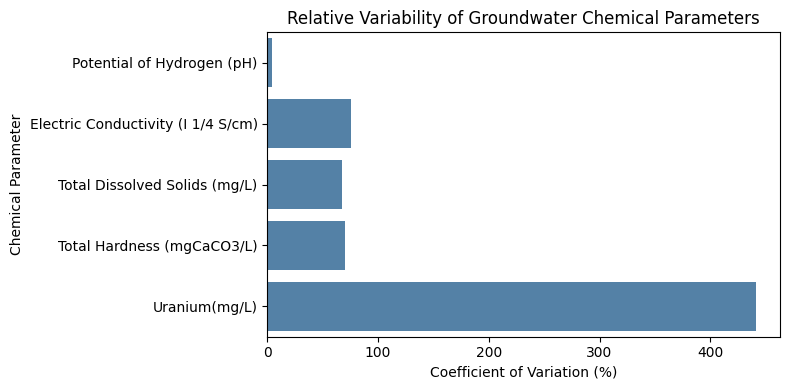

In [60]:
# Variance and Standard Deviation

variability = df[chemical_columns].agg(['var', 'std']).T
variability.columns = ['Variance', 'Standard Deviation']

display(variability.round(2))

# Coefficient of Variation (%) for comparing variability
variability['CV (%)'] = (
    variability['Standard Deviation'] /
    df[chemical_columns].mean() * 100
)

plt.figure(figsize=(8, 4))
sns.barplot(
    x=variability['CV (%)'],
    y=variability.index,
    color='steelblue'
)

plt.title('Relative Variability of Groundwater Chemical Parameters')
plt.xlabel('Coefficient of Variation (%)')
plt.ylabel('Chemical Parameter')
plt.tight_layout()
plt.show()

**Result & Interpretation**

The analysis measures the variability of groundwater chemical parameters using variance, standard deviation, and coefficient of variation. Electrical conductivity, TDS, and total hardness show considerable differences across groundwater samples. Uranium has the highest relative variability, indicating that its measured concentrations vary substantially compared with its mean. However, uranium and TDS have fewer available observations, so their results should be interpreted carefully. The findings highlight differences in groundwater chemical composition across the monitored samples.

,Skewness,Kurtosis
Potential of Hydrogen (pH),-1.23,9.34
Electric Conductivity (I 1/4 S/cm),2.49,9.47
Total Dissolved Solids (mg/L),2.52,9.77
Total Hardness (mgCaCO3/L),2.33,9.07
Uranium(mg/L),6.63,47.43


Hardness Outliers Detected: 17


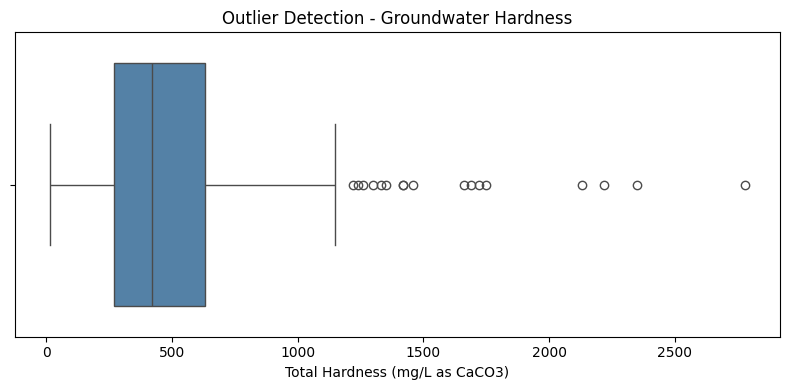

In [61]:
# Skewness, Kurtosis and Outlier Detection

shape_stats = df[chemical_columns].agg(['skew', 'kurt']).T
shape_stats.columns = ['Skewness', 'Kurtosis']
display(shape_stats.round(2))

# Detect outliers in Total Hardness using IQR
Q1 = df['Total Hardness (mgCaCO3/L)'].quantile(0.25)
Q3 = df['Total Hardness (mgCaCO3/L)'].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['Total Hardness (mgCaCO3/L)'] < lower_limit) |
    (df['Total Hardness (mgCaCO3/L)'] > upper_limit)
]

print("Hardness Outliers Detected:", len(outliers))

# Box Plot
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Total Hardness (mgCaCO3/L)'], color='steelblue')
plt.title('Outlier Detection - Groundwater Hardness')
plt.xlabel('Total Hardness (mg/L as CaCO3)')
plt.tight_layout()
plt.show()

**Result & Interpretation**

The analysis examines the distribution of groundwater chemical parameters using skewness, kurtosis, and the IQR method. Electrical conductivity, TDS, total hardness, and uranium show positively skewed distributions, indicating the presence of some unusually high measurements. Uranium has the highest skewness (6.63) and kurtosis (47.43). The box plot identifies 17 potential outliers in total hardness. These measurements are retained because they may represent important groundwater quality variations and require further investigation.

**Univariate Analysis — Chart 1: Groundwater pH Distribution**

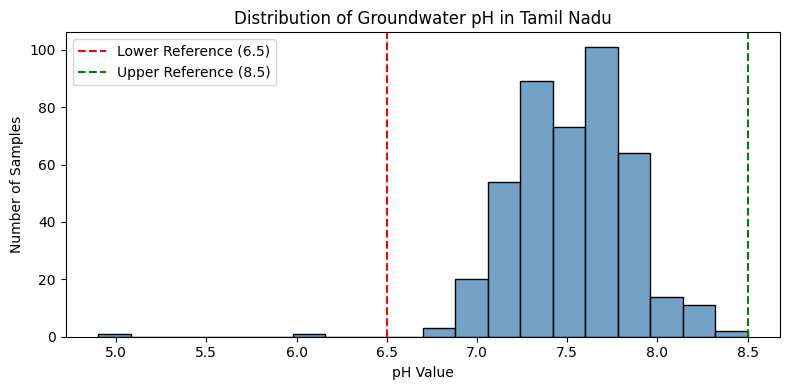

In [62]:
# Univariate Analysis 1 - Groundwater pH Distribution

plt.figure(figsize=(8, 4))

sns.histplot(
    data=df,
    x='Potential of Hydrogen (pH)',
    bins=20,
    color='steelblue',
    edgecolor='black'
)

plt.axvline(6.5, color='red', linestyle='--', label='Lower Reference (6.5)')
plt.axvline(8.5, color='green', linestyle='--', label='Upper Reference (8.5)')

plt.title('Distribution of Groundwater pH in Tamil Nadu')
plt.xlabel('pH Value')
plt.ylabel('Number of Samples')
plt.legend()
plt.tight_layout()
plt.show()

**Result & Interpretation**

The histogram shows the distribution of groundwater pH across Tamil Nadu using the Potential of Hydrogen (pH) column. Most samples have pH values between 7.0 and 8.0, indicating slightly alkaline groundwater. A few samples fall below the reference range of 6.5–8.5, suggesting that these locations may require further investigation. Overall, most recorded pH measurements fall within the selected reference range.

**Chart 2 — Distribution of Total Dissolved Solids (TDS)**

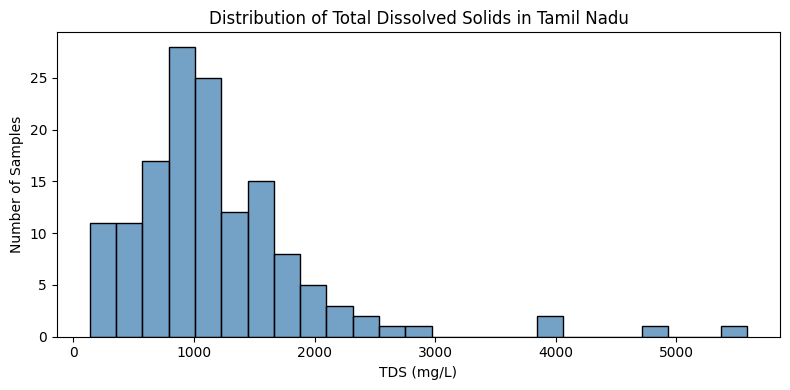

In [63]:
# Univariate Analysis 2 - TDS Distribution

plt.figure(figsize=(8, 4))

sns.histplot(
    data=df,
    x='Total Dissolved Solids (mg/L)',
    bins=25,
    color='steelblue',
    edgecolor='black'
)

plt.title('Distribution of Total Dissolved Solids in Tamil Nadu')
plt.xlabel('TDS (mg/L)')
plt.ylabel('Number of Samples')
plt.tight_layout()
plt.show()

**Result & Interpretation**

The histogram shows the distribution of Total Dissolved Solids (TDS) in groundwater samples across Tamil Nadu. Most measured values are concentrated between approximately 500 and 1,500 mg/L. The distribution is right-skewed, with a few unusually high values reaching 5,588 mg/L. These elevated measurements suggest that certain groundwater samples contain higher dissolved mineral concentrations and may require further investigation. The analysis is based on 143 available TDS measurements.

**Chart 3 — Distribution of Uranium Concentration**

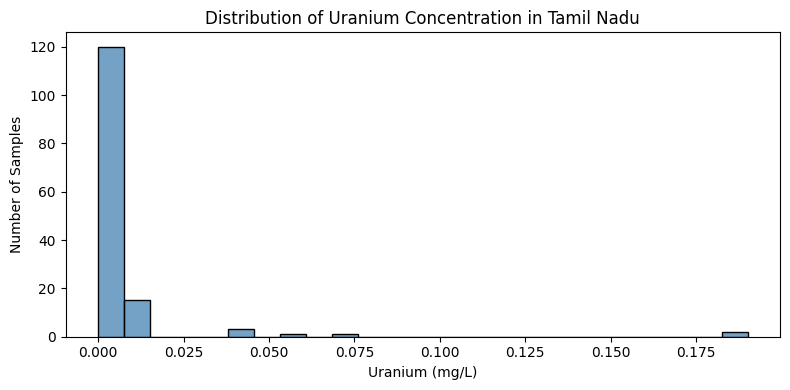

In [64]:
# Univariate Analysis 3 - Uranium Distribution

plt.figure(figsize=(8, 4))

sns.histplot(
    data=df,
    x='Uranium(mg/L)',
    bins=25,
    color='steelblue',
    edgecolor='black'
)

plt.title('Distribution of Uranium Concentration in Tamil Nadu')
plt.xlabel('Uranium (mg/L)')
plt.ylabel('Number of Samples')
plt.tight_layout()
plt.show()

**Result & Interpretation**

The histogram shows the distribution of uranium concentrations in groundwater samples across Tamil Nadu using the Uranium (mg/L) column. Most recorded concentrations are very low, while a few samples show unusually high values reaching approximately 0.19 mg/L. The distribution is strongly right-skewed, indicating that elevated uranium measurements occur in a small number of samples. These observations may require further investigation and monitoring. The analysis is based on 142 available uranium measurements.

**Chart 4 — Groundwater Sample Count by District**

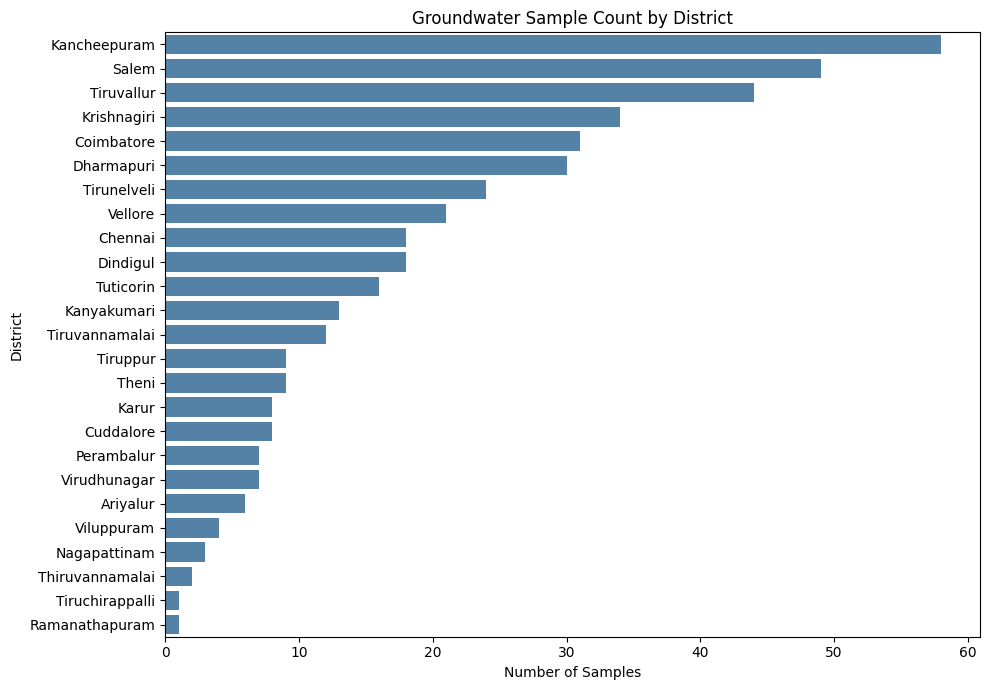

In [65]:
# Univariate Analysis 4 - Groundwater Samples by District

district_counts = df['District'].value_counts()

plt.figure(figsize=(10, 7))
sns.barplot(
    x=district_counts.values,
    y=district_counts.index,
    color='steelblue'
)

plt.title('Groundwater Sample Count by District')
plt.xlabel('Number of Samples')
plt.ylabel('District')
plt.tight_layout()
plt.show()

**Result & Interpretation**

The bar chart shows the distribution of groundwater samples across 25 districts in Tamil Nadu. Kancheepuram has the highest number of recorded samples, followed by Salem and Tiruvallur. Some districts, including Ramanathapuram and Tiruchirappalli, have comparatively fewer observations. This uneven sampling coverage may affect district-wise comparisons. Therefore, the findings should be interpreted carefully, and additional sampling is recommended in districts with limited records.

**Chart 5 — Groundwater pH Category Distribution**

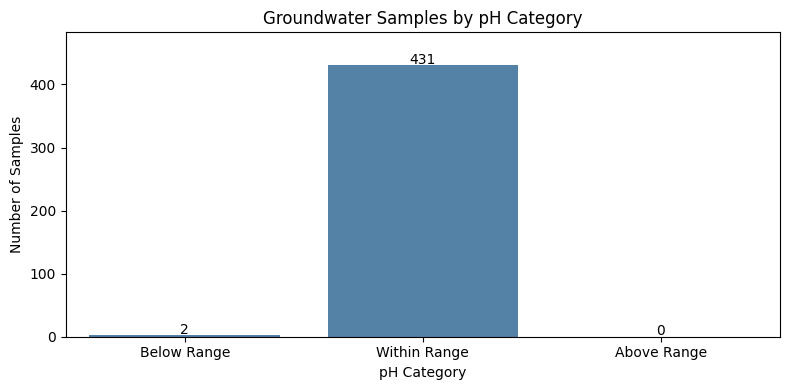

In [66]:
# Univariate Analysis 5 - pH Category Distribution

ph_counts = df['pH_Category'].value_counts().reindex(
    ['Below Range', 'Within Range', 'Above Range'], fill_value=0
)

plt.figure(figsize=(8, 4))

ax = sns.barplot(
    x=ph_counts.index,
    y=ph_counts.values,
    color='steelblue'
)

for i, count in enumerate(ph_counts.values):
    ax.text(i, count + 2, str(count), ha='center')

plt.title('Groundwater Samples by pH Category')
plt.xlabel('pH Category')
plt.ylabel('Number of Samples')
plt.ylim(0, max(ph_counts.values) * 1.12)
plt.tight_layout()
plt.show()

**Result & Interpretation**

The bar chart classifies groundwater samples using the pH_Category column. Out of 433 samples, 431 (99.54%) fall within the selected pH reference range of 6.5–8.5, while only 2 samples (0.46%) fall below the range. No samples exceed the upper reference value. This indicates that most recorded groundwater samples have pH values within the selected range, while the two low-pH samples may require further investigation.

**Bivariate Analysis**

**Chart 1: District vs Median Total Hardness**

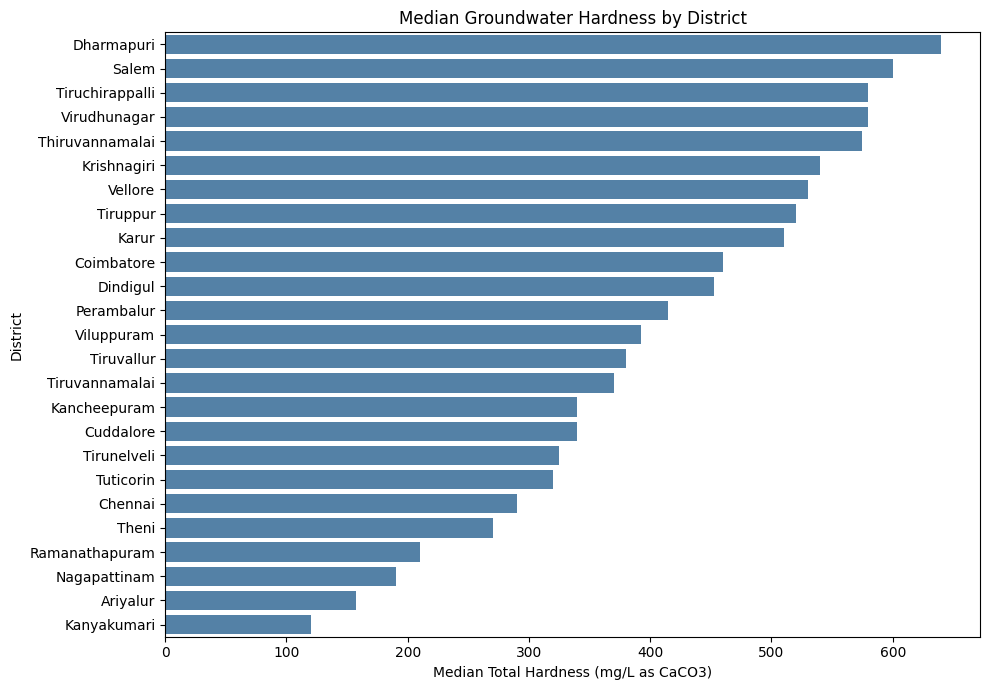

In [67]:
# Bivariate Analysis 1 - District vs Median Total Hardness

district_hardness = (
    df.groupby('District')['Total Hardness (mgCaCO3/L)']
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=district_hardness.values,
    y=district_hardness.index,
    color='steelblue'
)

plt.title('Median Groundwater Hardness by District')
plt.xlabel('Median Total Hardness (mg/L as CaCO3)')
plt.ylabel('District')
plt.tight_layout()
plt.show()

**Result & Interpretation**

The horizontal bar chart compares median groundwater hardness across 25 districts in Tamil Nadu using the District and Total Hardness columns. Dharmapuri records the highest median hardness, followed by Salem, Tiruchirappalli, and Virudhunagar, while Kanyakumari has the lowest. This indicates considerable variation in groundwater hardness across districts. Districts with higher median hardness may require closer monitoring, although differences in sample counts should be considered before drawing district-wide conclusions.

**Chart 2 — Electrical Conductivity vs Total Dissolved Solids (TDS)**

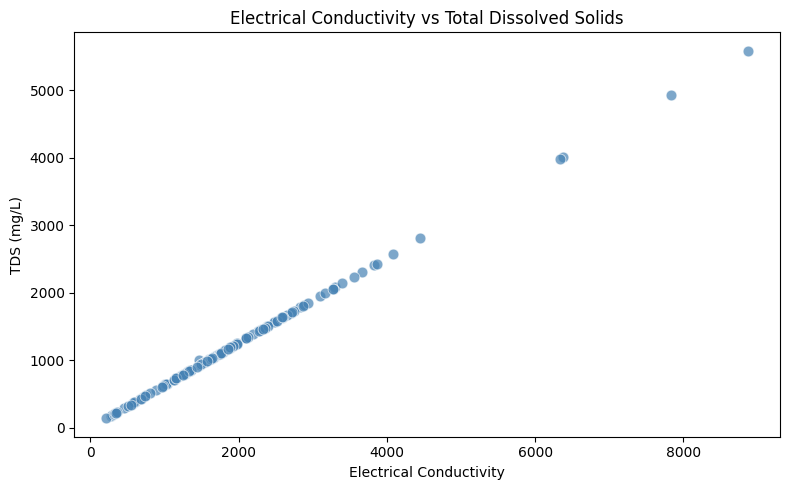

In [68]:
# Bivariate Analysis 2 - EC vs TDS

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Electric Conductivity (I 1/4 S/cm)',
    y='Total Dissolved Solids (mg/L)',
    color='steelblue',
    alpha=0.7,
    s=60
)

plt.title('Electrical Conductivity vs Total Dissolved Solids')
plt.xlabel('Electrical Conductivity')
plt.ylabel('TDS (mg/L)')
plt.tight_layout()
plt.show()

**Result & Interpretation**

The scatter plot examines the relationship between Electrical Conductivity (EC) and Total Dissolved Solids (TDS) in groundwater samples. The chart shows a strong positive linear relationship, indicating that samples with higher electrical conductivity generally have higher dissolved solids concentrations. A few samples show particularly high values for both parameters. This suggests that electrical conductivity may be a useful indicator of dissolved mineral content in groundwater. The analysis uses 143 samples with available TDS measurements.

**Chart 3 — Year-wise Median Groundwater Hardness**

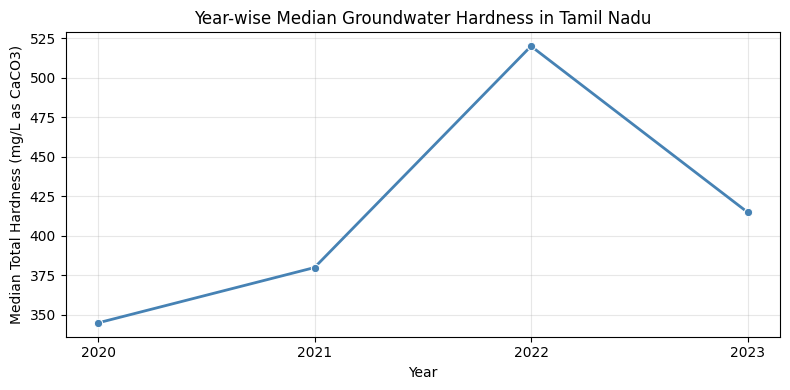

In [69]:
# Bivariate Analysis 3 - Year-wise Median Groundwater Hardness

yearly_hardness = (
    df.groupby('Sampling_Year')['Total Hardness (mgCaCO3/L)']
    .median()
    .sort_index()
)

plt.figure(figsize=(8, 4))

sns.lineplot(
    x=yearly_hardness.index,
    y=yearly_hardness.values,
    marker='o',
    color='steelblue',
    linewidth=2
)

plt.title('Year-wise Median Groundwater Hardness in Tamil Nadu')
plt.xlabel('Year')
plt.ylabel('Median Total Hardness (mg/L as CaCO3)')
plt.xticks(yearly_hardness.index)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Result & Interpretation**

The line chart compares median groundwater hardness from 2020 to 2023 using the Sampling_Year and Total Hardness columns. Median hardness increased from approximately 345 mg/L in 2020 to 520 mg/L in 2022, followed by a decrease to approximately 415 mg/L in 2023. This indicates variation in hardness measurements across the recorded years. However, 2023 contains only four samples, and sampling coverage differs between years, so the trend should not be interpreted as a confirmed statewide change in groundwater quality.

**Chart 4 — District-wise Median Uranium Concentration**

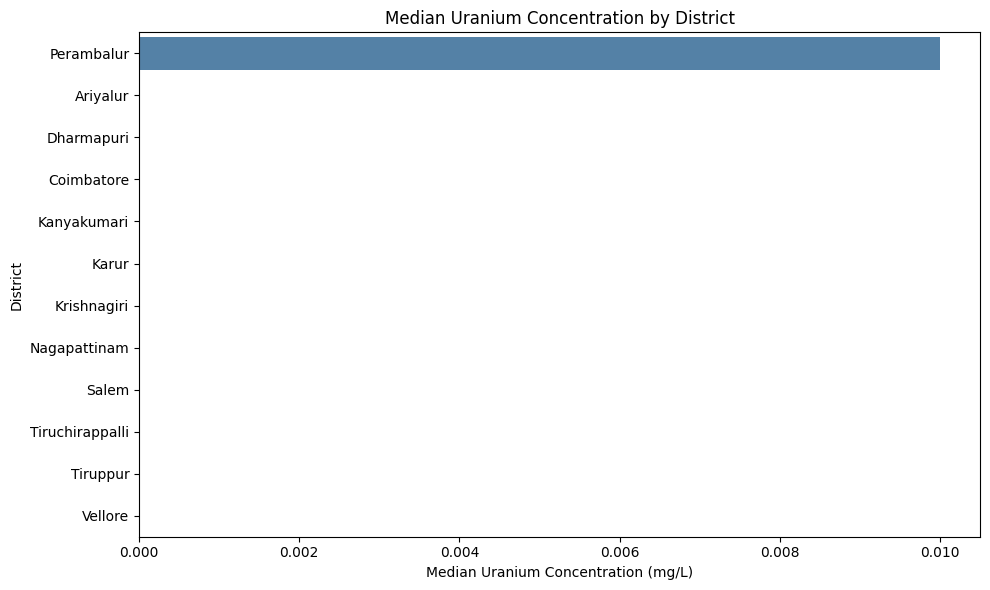

In [70]:
# Bivariate Analysis 4 - District-wise Median Uranium

district_uranium = (
    df.groupby('District')['Uranium(mg/L)']
    .agg(['median', 'count'])
    .query('count > 0')
    .sort_values('median', ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=district_uranium['median'],
    y=district_uranium.index,
    color='steelblue'
)

plt.title('Median Uranium Concentration by District')
plt.xlabel('Median Uranium Concentration (mg/L)')
plt.ylabel('District')
plt.tight_layout()
plt.show()

**Result & Interpretation**

The horizontal bar chart compares median uranium concentrations across districts with available measurements using the District and Uranium (mg/L) columns. Perambalur records the highest median uranium concentration at approximately 0.010 mg/L, while the other displayed districts have median values close to zero. This highlights differences in recorded uranium concentrations and suggests that Perambalur may benefit from further investigation. However, the findings are limited by incomplete uranium data and unequal sample availability across districts.

**Multivariate Analysis**

**Chart 1 — Groundwater Chemical Correlation Heatmap**

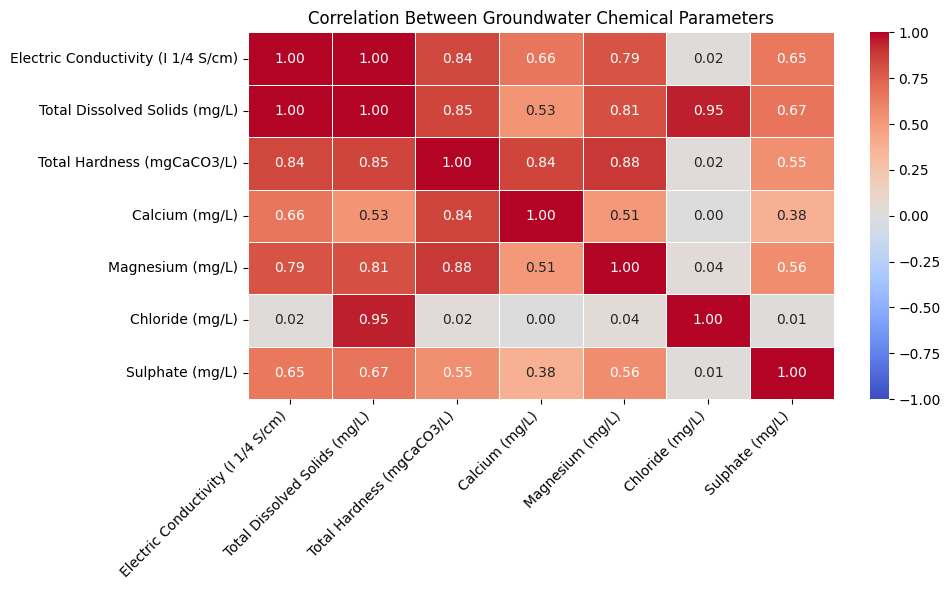

In [71]:
# Multivariate Analysis 1 - Chemical Correlation Heatmap

correlation_columns = [
    'Electric Conductivity (I 1/4 S/cm)',
    'Total Dissolved Solids (mg/L)',
    'Total Hardness (mgCaCO3/L)',
    'Calcium (mg/L)',
    'Magnesium (mg/L)',
    'Chloride (mg/L)',
    'Sulphate (mg/L)'
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Groundwater Chemical Parameters')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Result & Interpretation**

The correlation heatmap examines relationships among seven groundwater chemical parameters. Electrical Conductivity and TDS show a very strong positive correlation (1.00). Total Hardness is strongly correlated with Magnesium (0.88) and Calcium (0.84), indicating that higher hardness measurements are associated with higher concentrations of these minerals. TDS and Chloride also show a strong positive correlation (0.95). These findings help identify related groundwater quality indicators. However, correlations involving missing measurements should be interpreted carefully, and correlation does not establish causation.

**Chart 2 — District-wise Groundwater Chemical Profile Heatmap**

<Axes: ylabel='District'>

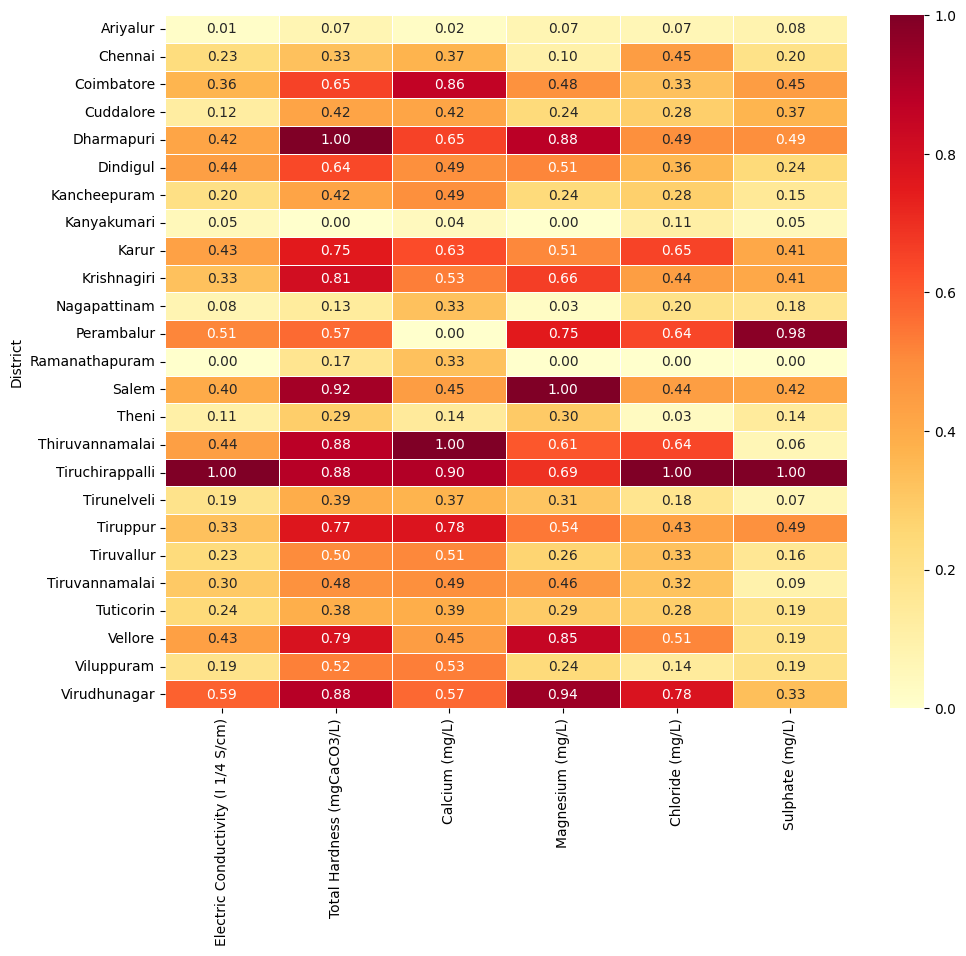

In [72]:
# Multivariate Analysis 2 - District-wise Chemical Profile

parameters = [
    'Electric Conductivity (I 1/4 S/cm)',
    'Total Hardness (mgCaCO3/L)',
    'Calcium (mg/L)',
    'Magnesium (mg/L)',
    'Chloride (mg/L)',
    'Sulphate (mg/L)'
]

# Calculate district-wise median values
district_profile = df.groupby('District')[parameters].median()

# Normalize each parameter to a 0-1 scale
normalized_profile = (
    (district_profile - district_profile.min()) /
    (district_profile.max() - district_profile.min())
)

# Create Heatmap
plt.figure(figsize=(11, 9))

sns.heatmap(
    normalized_profile,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.4
)

**Result & Interpretation**

The heatmap compares six groundwater chemical parameters across 25 districts using district-wise median values. Each parameter is normalized to a 0–1 scale to make district comparisons easier. Tiruchirappalli shows relatively high electrical conductivity, chloride, and sulphate measurements, while Salem shows higher calcium and magnesium levels. These differences indicate that groundwater chemical composition varies between districts. The findings can help prioritize further groundwater testing, but normalized values do not directly indicate contamination or drinking-water safety.

**Chart 3: District × Year Groundwater Hardness Heatmap**

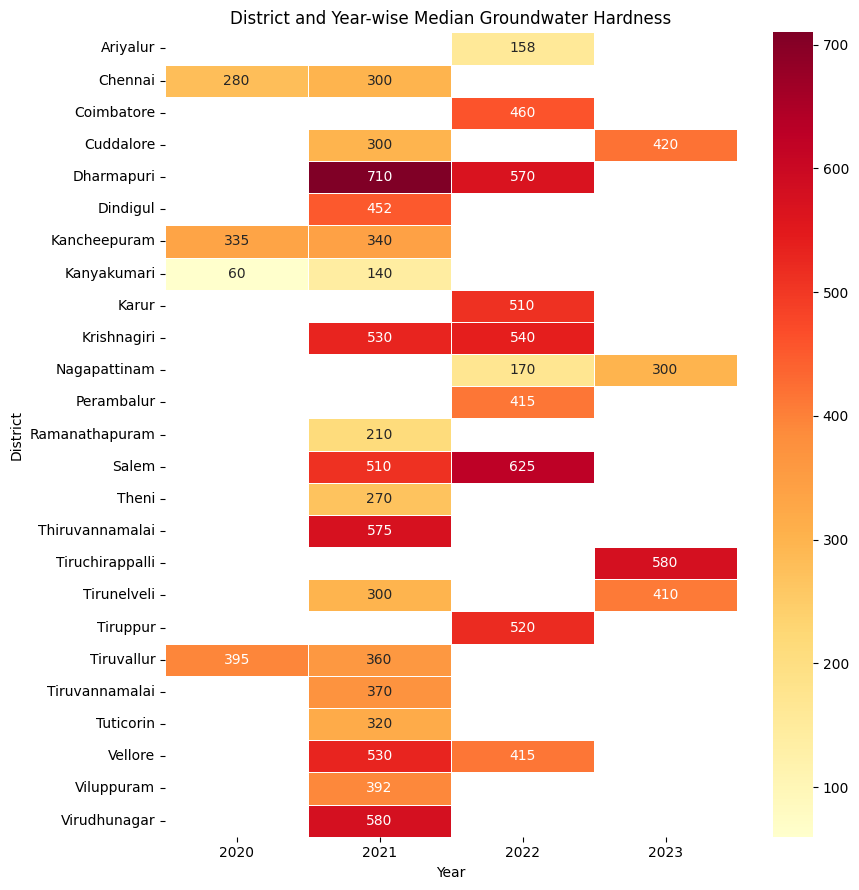

In [73]:
# Multivariate Analysis 3 - District × Year Groundwater Hardness

district_year_hardness = df.pivot_table(
    index='District',
    columns='Sampling_Year',
    values='Total Hardness (mgCaCO3/L)',
    aggfunc='median'
)

plt.figure(figsize=(9, 9))

sns.heatmap(
    district_year_hardness,
    annot=True,
    fmt='.0f',
    cmap='YlOrRd',
    linewidths=0.5,
    mask=district_year_hardness.isna()
)

plt.title('District and Year-wise Median Groundwater Hardness')
plt.xlabel('Year')
plt.ylabel('District')
plt.tight_layout()
plt.show()

**Result & Interpretation**

The heatmap compares median groundwater hardness across districts and years using the District, Sampling_Year, and Total Hardness columns. Dharmapuri recorded the highest displayed median hardness of 710 mg/L in 2021, followed by Salem with 625 mg/L in 2022. Kanyakumari recorded a comparatively low median of 60 mg/L in 2020. The chart highlights differences in groundwater hardness across locations and years. Blank cells indicate unavailable district-year observations. Uneven sampling coverage limits direct comparisons and requires careful interpretation.

**Summary of Findings**

This project analyzed 433 groundwater records from 25 districts in Tamil Nadu, covering 2020–2023. The analysis identified differences in groundwater chemical composition, district-wise hardness levels, and uranium concentrations. Electrical Conductivity and Total Dissolved Solids showed a strong positive relationship. The findings highlight locations and chemical parameters that may require further groundwater monitoring.

**Key Insights**

Groundwater pH: 431 out of 433 samples (99.54%) fall within the selected pH reference range of 6.5–8.5.

Groundwater Hardness: Dharmapuri and Salem recorded relatively high district-wise median hardness, indicating the need for closer monitoring.

Uranium Concentration: Most available uranium measurements were low, but a few samples showed unusually high concentrations, reaching approximately 0.19 mg/L.

Chemical Relationships: Electrical Conductivity and Total Dissolved Solids showed a very strong positive correlation, suggesting that EC can help indicate dissolved mineral content.

Monitoring Coverage: Groundwater records were unevenly distributed across districts and years. Additional sampling would improve the reliability of comparisons.

**Types of Analysis**

**1. Descriptive Analysis — What Happened?**

Analyzed 433 groundwater records from 25 districts to understand pH, electrical conductivity, TDS, hardness, and uranium concentrations using summary statistics and visualizations.

**2. Diagnostic Analysis — Why Might It Have Happened?**

Examined relationships between groundwater chemical parameters and compared district-wise measurements. Strong relationships between EC and TDS, and between hardness, calcium, and magnesium, help explain variations in groundwater composition.

**3. Predictive Analysis — What Could Happen?**

Predictive modeling was not performed in this project. Future analysis could use historical groundwater measurements to estimate chemical concentrations or identify locations at risk of elevated contamination.

**4. Prescriptive Analysis — What Should Be Done?**

Based on the findings, prioritize further groundwater testing in locations with unusually high chemical measurements and improve monitoring coverage in districts with limited records.

**Recommendations / Decision Support**

**Prioritize Groundwater Monitoring: **Conduct further testing in locations with higher recorded groundwater hardness, particularly Dharmapuri and Salem.

**Investigate Elevated Uranium:** Retest groundwater samples with unusually high uranium concentrations and identify the affected monitoring locations.

**Monitor Dissolved Minerals:** Use electrical conductivity measurements alongside laboratory TDS testing to identify changes in dissolved mineral content.

**Improve Data Collection:** Increase sampling in districts with fewer records and ensure consistent monitoring across years.

**Support Water Quality Decisions:** Compare chemical measurements against applicable drinking-water standards before recommending treatment or declaring water safe for consumption.

**Future Enhancements**

**Expand the Dataset: **Include more recent groundwater records and additional sampling locations to improve the reliability of the analysis.

**Automate Data Analysis:** Develop automated Python scripts or interactive dashboards to monitor groundwater quality more efficiently.

**Predict Groundwater Quality:** Apply machine learning models to predict chemical concentrations and identify potential contamination risks using historical data.

**Geographical Mapping:** Use GIS-based maps to visualize groundwater quality patterns and identify locations requiring closer monitoring.